# Superstore EDA — Bright Insights

This exploratory notebook informs a focused regional sales manager dashboard. Source: [Vivek Chowdhury’s Superstore dataset on Kaggle](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final). This is a fictitious/sample retail business dataset; conclusions describe this file, not a verified live retailer. One row is an order line. The dashboard’s design rationale is in `README.md`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
%matplotlib inline

pd.set_option('display.max_columns', 25)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('superstore.csv', encoding='cp1252')
print('Python:', sys.version.split()[0])
print('Original shape:', df.shape)
display(df.head())
display(df.dtypes.to_frame('Original dtype'))

Python: 3.14.7
Original shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


,Original dtype
Row ID,int64
Order ID,str
Order Date,str
Ship Date,str
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
Country,str
City,str


The input has 9,994 lines and 21 columns. Dates arrive as text and must be parsed before a trend is computed. Postal codes and identifiers are labels; their numeric appearance does not make them quantitative business measures.

In [2]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
display(df.isna().sum().to_frame('Missing values'))
print('Duplicate full rows:', df.duplicated().sum())
print('Duplicate Row IDs:', df['Row ID'].duplicated().sum())
print('Distinct orders:', df['Order ID'].nunique())
print('Date range:', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())
print('Order lines:', len(df))
print('Ship dates before order dates:', (df['Ship Date'] < df['Order Date']).sum())
print('Observed months:', df['Order Date'].dt.to_period('M').nunique())
display(df[['Sales','Quantity','Discount','Profit']].describe().round(2))

,Missing values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Duplicate full rows: 0
Duplicate Row IDs: 0
Distinct orders: 5009
Date range: 2014-01-03 to 2017-12-30
Order lines: 9994
Ship dates before order dates: 0
Observed months: 48


,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


There are no missing cells, duplicated full rows or duplicated Row IDs. The 9,994 lines belong to 5,009 orders and cover all 48 months from January 2014 to December 2017. Repeated Order IDs are expected because an order can have several products; removing them would erase valid order lines. No blanket imputation or deduplication is applied.

,Value
Sales,2297200.86
Reported profit,286397.02
Margin (%),12.47
Loss-making lines,1871.00
Loss-making lines (%),18.72
Median line sales,54.49
Largest line sales,22638.48


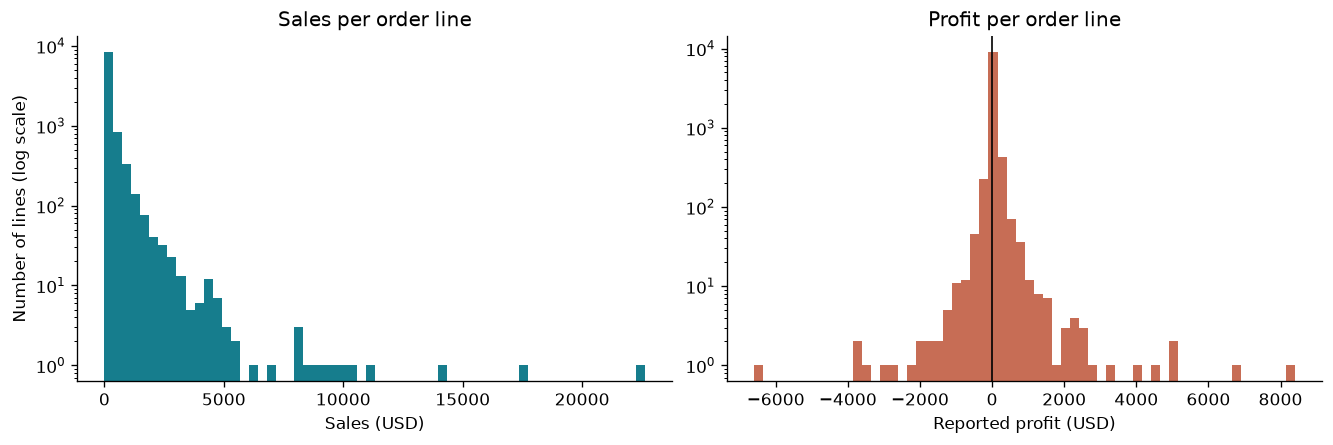

In [3]:
totals = pd.Series({
    'Sales': df['Sales'].sum(),
    'Reported profit': df['Profit'].sum(),
    'Margin (%)': 100 * df['Profit'].sum() / df['Sales'].sum(),
    'Loss-making lines': (df['Profit'] < 0).sum(),
    'Loss-making lines (%)': 100 * (df['Profit'] < 0).mean(),
    'Median line sales': df['Sales'].median(),
    'Largest line sales': df['Sales'].max(),
})
display(totals.round(2).to_frame('Value'))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout='constrained')
axes[0].hist(df['Sales'], bins=60, color='#167D8D')
axes[0].set(title='Sales per order line', xlabel='Sales (USD)', ylabel='Number of lines')
axes[0].set_yscale('log')
axes[0].set_ylabel('Number of lines (log scale)')
axes[1].hist(df['Profit'], bins=60, color='#C76D55')
axes[1].set(title='Profit per order line', xlabel='Reported profit (USD)')
axes[1].set_yscale('log')
axes[1].axvline(0, color='black', linewidth=1)
plt.show()

Total sales are $2,297,200.86 and reported profit is $286,397.02, a 12.47% weighted margin. Yet 1,871 lines (18.72%) lose money. The median sales line is $54.49 and the maximum is $22,638.48, so totals can be influenced by a few large transactions. Both distributions use a logarithmic count axis to expose the long tails; values are not clipped or deleted.

,Sales,Profit,Margin (%)
Region,,,
Central,501239.89,39706.36,7.92
East,678781.24,91522.78,13.48
South,391721.90,46749.43,11.93
West,725457.82,108418.45,14.94


,Sales,Profit
Sub-Category,,
Tables,206965.53,-17725.48
Bookcases,114880.00,-3472.56
Supplies,46673.54,-1189.10
Fasteners,3024.28,949.52
Machines,189238.63,3384.76
Labels,12486.31,5546.25
Art,27118.79,6527.79
Envelopes,16476.40,6964.18
Furnishings,91705.16,13059.14


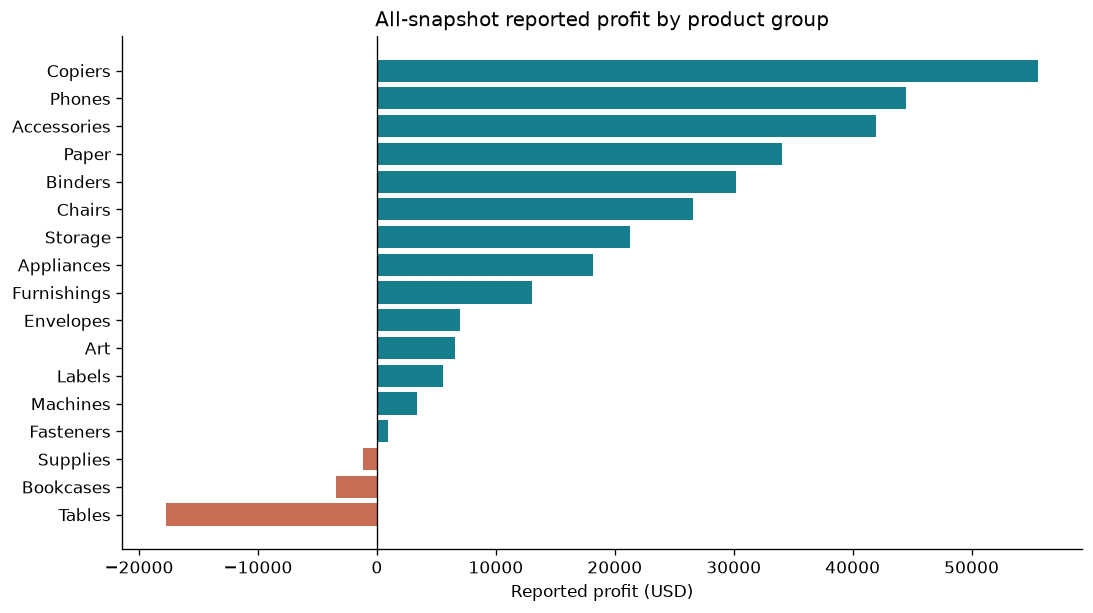

In [4]:
region = df.groupby('Region')[['Sales','Profit']].sum()
region['Margin (%)'] = 100 * region['Profit'] / region['Sales']
display(region.round(2))
product = df.groupby('Sub-Category')[['Sales','Profit']].sum().sort_values('Profit')
display(product.round(2))
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
ax.barh(product.index, product['Profit'], color=['#C76D55' if x < 0 else '#167D8D' for x in product['Profit']])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='All-snapshot reported profit by product group', xlabel='Reported profit (USD)')
plt.show()

Tables lose $17,725.48, Bookcases lose $3,472.56 and Supplies lose $1,189.10, despite the positive total margin. This supports a product-group profit chart instead of a sales-only ranking. A region selector matters because a regional manager must inspect the numbers within their authority; the all-region totals are context, not the app’s default scope.

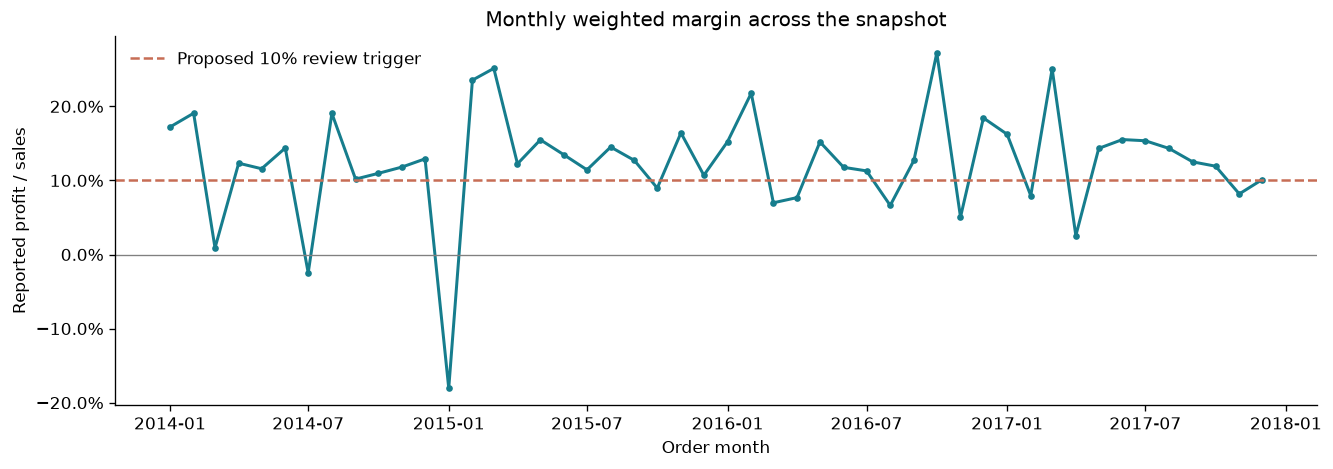

Months below proposed 10% threshold: 11 of 48


,Sales,Profit,Margin
Order Date,,,
2014-01,14236.895,2450.191,0.172
2014-02,4519.892,862.308,0.191
2014-03,55691.009,498.730,0.009
2014-04,28295.345,3488.835,0.123
2014-05,23648.287,2738.710,0.116
2014-06,34595.128,4976.524,0.144
2014-07,33946.393,-841.483,-0.025
2014-08,27909.468,5318.105,0.191
2014-09,81777.351,8328.099,0.102


In [5]:
monthly = df.groupby(df['Order Date'].dt.to_period('M'))[['Sales','Profit']].sum()
monthly['Margin'] = monthly['Profit'] / monthly['Sales']
fig, ax = plt.subplots(figsize=(11, 3.8), layout='constrained')
ax.plot(monthly.index.to_timestamp(), monthly['Margin'], color='#167D8D', marker='.', linewidth=1.8)
ax.axhline(.10, linestyle='--', color='#C76D55', label='Proposed 10% review trigger')
ax.axhline(0, color='gray', linewidth=.8)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Monthly weighted margin across the snapshot', ylabel='Reported profit / sales', xlabel='Order month')
ax.legend(frameon=False)
plt.show()
print('Months below proposed 10% threshold:', int((monthly['Margin'] < .10).sum()), 'of', len(monthly))
display(monthly[['Sales','Profit','Margin']].head(12).round(3))

Monthly fluctuations make a trend useful for repeated review: the annual total can conceal a weak month. The 10% line is a proposed management trigger for investigation, not a statistical result or a verified corporate target. Production reviews should use completed months; this historical dashboard shows a full selected calendar year.

,Sales,Profit,Lines,Margin (%)
Discount,,,,
0.00,1087908.47,320987.60,4798,29.51
0.10,54369.35,9029.18,94,16.61
0.15,27558.52,1418.99,52,5.15
0.20,764594.37,90337.31,3657,11.82
0.30,103226.66,-10369.28,227,-10.05
0.32,14493.46,-2391.14,27,-16.50
0.40,116417.78,-23057.05,206,-19.81
0.45,5484.97,-2493.11,11,-45.45
0.50,58918.54,-20506.43,66,-34.80


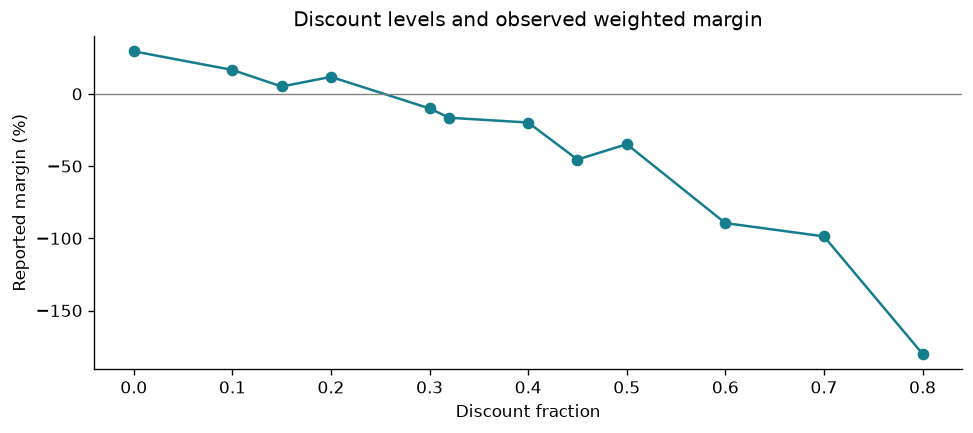

,Sales,Profit
Segment,,
Consumer,1161401.34,134119.21
Corporate,706146.37,91979.13
Home Office,429653.15,60298.68


In [6]:
discount = df.groupby('Discount').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Lines=('Row ID','size'))
discount['Margin (%)'] = 100 * discount['Profit'] / discount['Sales']
display(discount.round(2))
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
ax.plot(discount.index, discount['Margin (%)'], marker='o', color='#167D8D')
ax.axhline(0, color='gray', linewidth=.8)
ax.set(title='Discount levels and observed weighted margin', xlabel='Discount fraction', ylabel='Reported margin (%)')
plt.show()
display(df.groupby('Segment')[['Sales','Profit']].sum().round(2))

Higher discount levels coincide with weak or negative margins in several groups, suggesting a cost-and-discount review. This is an association: product mix, regional policy and underlying costs can confound it, so the app does not recommend an automatic price change. The discount relationship stays in the EDA rather than becoming a third dashboard chart. Segment totals are also omitted from the dashboard because they do not prioritize loss-making product groups for this manager.

In [7]:
# Independently check the dashboard's default region and latest-year scope.
view = df[(df['Region'] == 'Central') & (df['Order Date'].dt.year == 2017)]
print('Default region/year: Central, 2017')
print(f"Sales: ${view['Sales'].sum():,.2f}")
print(f"Reported profit: ${view['Profit'].sum():,.2f}")
print(f"Margin: {view['Profit'].sum()/view['Sales'].sum():.2%}")
print('Order lines:', len(view), '| Distinct orders:', view['Order ID'].nunique())
display(view.groupby('Sub-Category')['Profit'].sum().sort_values().round(2).to_frame('Reported profit'))

Default region/year: Central, 2017
Sales: $147,098.13
Reported profit: $7,550.84
Margin: 5.13%
Order lines: 778 | Distinct orders: 406


,Reported profit
Sub-Category,
Binders,-3957.14
Tables,-2162.85
Furnishings,-1319.68
Bookcases,-511.03
Appliances,-313.38
Fasteners,112.23
Supplies,117.72
Labels,259.83
Storage,409.00


The dashboard keeps three KPIs, two charts and two filters. Weighted margin, order-line counts and the original negative profits are preserved. The CSV is frozen; a real implementation would refresh nightly, be reviewed each Monday, show a load timestamp and flag failed refreshes. See the README for the layout rationale and limitations.